# 03 — Evaluation

Load the fine-tuned model and evaluate on the held-out test set.
Produces:
- Per-class precision / recall / F1
- Confusion matrix heatmap
- Misclassification examples

> **Kernel:** `Legal AI`

In [6]:
import json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import yaml
from datasets import load_from_disk
from IPython.display import display
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from transformers import AutoModelForSequenceClassification, AutoTokenizer

ROOT = Path().resolve().parent
with open(ROOT / 'config.yaml') as f:
    CFG = yaml.safe_load(f)

PROCESSED_DIR  = ROOT / CFG['dataset']['processed_dir']
MODEL_DIR      = ROOT / CFG['training']['output_dir'] / 'best_model'
EVAL_OUT       = ROOT / CFG['training']['output_dir'] / 'evaluation'
EVAL_OUT.mkdir(parents=True, exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {DEVICE}')

Device: cuda


## 1. Load model & test dataset

In [7]:
if not MODEL_DIR.exists():
    raise FileNotFoundError('Model not found. Run 02_finetune.ipynb first.')

tokenizer = AutoTokenizer.from_pretrained(str(MODEL_DIR))
model     = AutoModelForSequenceClassification.from_pretrained(str(MODEL_DIR)).to(DEVICE)
model.eval()

dataset_dir = PROCESSED_DIR / 'hf_dataset'
ds          = load_from_disk(str(dataset_dir))
test_ds     = ds['test']

with open(dataset_dir / 'id2label.json') as f:
    id2label = {int(k): v for k, v in json.load(f).items()}

print(f'Test samples: {len(test_ds):,}  |  Classes: {len(id2label)}')

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Test samples: 2,075  |  Classes: 48


## 2. Run inference on full test set

In [8]:
BATCH_SIZE = 32
all_preds, all_labels, all_probs = [], [], []

for i in range(0, len(test_ds), BATCH_SIZE):
    batch = test_ds[i : i + BATCH_SIZE]
    ids   = torch.tensor(batch['input_ids']).to(DEVICE)
    mask  = torch.tensor(batch['attention_mask']).to(DEVICE)

    with torch.no_grad():
        out = model(input_ids=ids, attention_mask=mask)

    probs = torch.softmax(out.logits, dim=-1).cpu().numpy()
    preds = np.argmax(probs, axis=-1)

    all_preds.extend(preds)
    all_probs.extend(probs)
    all_labels.extend(batch['labels'])

    if i % (BATCH_SIZE * 10) == 0:
        print(f'  {i}/{len(test_ds)}')

y_pred = np.array(all_preds)
y_true = np.array(all_labels)
probs  = np.array(all_probs)

print(f'\nAccuracy: {accuracy_score(y_true, y_pred):.4f}')
print(f'Macro F1: {f1_score(y_true, y_pred, average="macro"):.4f}')

  0/2075
  320/2075
  640/2075
  960/2075
  1280/2075
  1600/2075
  1920/2075

Accuracy: 0.8983
Macro F1: 0.7233


## 3. Per-class classification report

In [9]:
# Only use label IDs that actually appear in y_true or y_pred
# (test split may not contain every class that was in training)
present_ids   = sorted(set(y_true) | set(y_pred))
label_names   = [id2label[i] for i in present_ids]

report_str  = classification_report(
    y_true, y_pred,
    labels=present_ids,
    target_names=label_names,
    zero_division=0,
)
print(report_str)

# Save
report_dict = classification_report(
    y_true, y_pred,
    labels=present_ids,
    target_names=label_names,
    output_dict=True,
    zero_division=0,
)
with open(EVAL_OUT / 'metrics.json', 'w') as f:
    json.dump({'accuracy': float(accuracy_score(y_true, y_pred)),
               'macro_f1': float(f1_score(y_true, y_pred, average='macro', zero_division=0)),
               'per_class': report_dict}, f, indent=2)
print(f'Saved -> {EVAL_OUT}/metrics.json')


                                       precision    recall  f1-score   support

           Affiliate License-Licensee       0.50      0.12      0.20         8
           Affiliate License-Licensor       1.00      0.50      0.67         4
                       Agreement Date       0.94      0.99      0.96        69
                      Anti-Assignment       0.92      0.97      0.94        97
                         Audit Rights       0.95      0.99      0.97       106
                     Cap On Liability       0.95      0.88      0.91        78
                    Change Of Control       0.91      0.83      0.87        36
                  Covenant Not To Sue       0.95      0.97      0.96        37
                        Document Name       0.96      1.00      0.98        86
                       Effective Date       0.87      0.82      0.84        33
                          Exclusivity       0.72      0.67      0.69        61
                      Expiration Date       0.91   

## 4. Confusion matrix

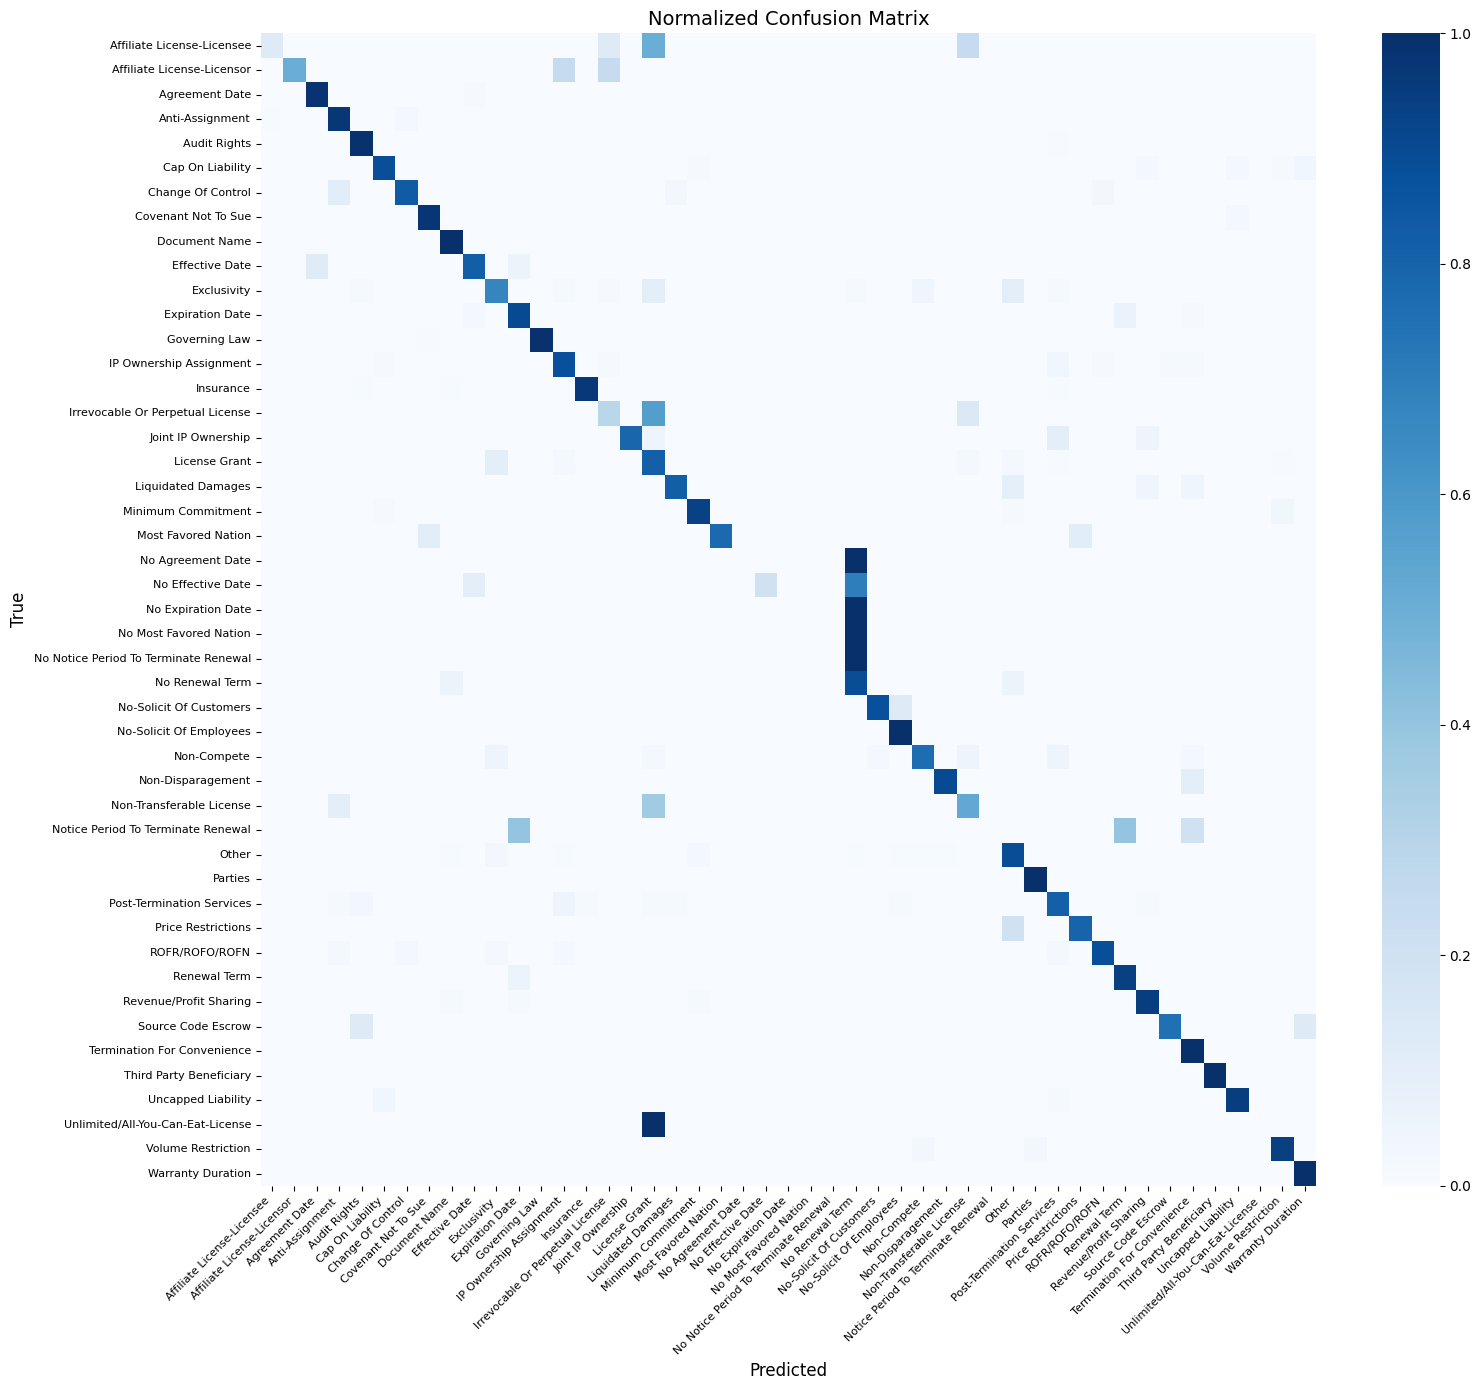

Saved -> models\finetuned\evaluation/confusion_matrix.png


In [10]:
cm      = confusion_matrix(y_true, y_pred, labels=present_ids)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(cm_norm, xticklabels=label_names, yticklabels=label_names,
            annot=False, cmap='Blues', ax=ax, vmin=0, vmax=1)
ax.set_xlabel('Predicted', fontsize=12)
ax.set_ylabel('True',      fontsize=12)
ax.set_title('Normalized Confusion Matrix', fontsize=14)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.savefig(EVAL_OUT / 'confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {EVAL_OUT}/confusion_matrix.png')


## 5. Error analysis — top misclassifications

In [11]:
errors = [
    {'true': id2label[t], 'predicted': id2label[p], 'confidence': float(np.max(pr))}
    for t, p, pr in zip(y_true, y_pred, probs) if t != p
]
err_df = pd.DataFrame(errors).sort_values('confidence', ascending=False)
err_df.to_csv(EVAL_OUT / 'misclassifications.csv', index=False)

print(f'Total errors: {len(err_df)} / {len(y_true)} ({100*len(err_df)/len(y_true):.1f}%)')
print('\nTop confusion pairs:')
display(
    err_df.groupby(['true', 'predicted']).size()
           .reset_index(name='count')
           .sort_values('count', ascending=False)
           .head(15)
)

Total errors: 211 / 2075 (10.2%)

Top confusion pairs:


,true,predicted,count
46,License Grant,Exclusivity,9
62,No Effective Date,No Renewal Term,7
64,No Most Favored Nation,No Renewal Term,7
77,Non-Transferable License,License Grant,7
26,Exclusivity,Other,6
23,Exclusivity,License Grant,6
65,No Notice Period To Terminate Renewal,No Renewal Term,5
29,Expiration Date,Renewal Term,5
18,Effective Date,Agreement Date,4
41,Irrevocable Or Perpetual License,License Grant,4


## 6. F1 per class — bar chart

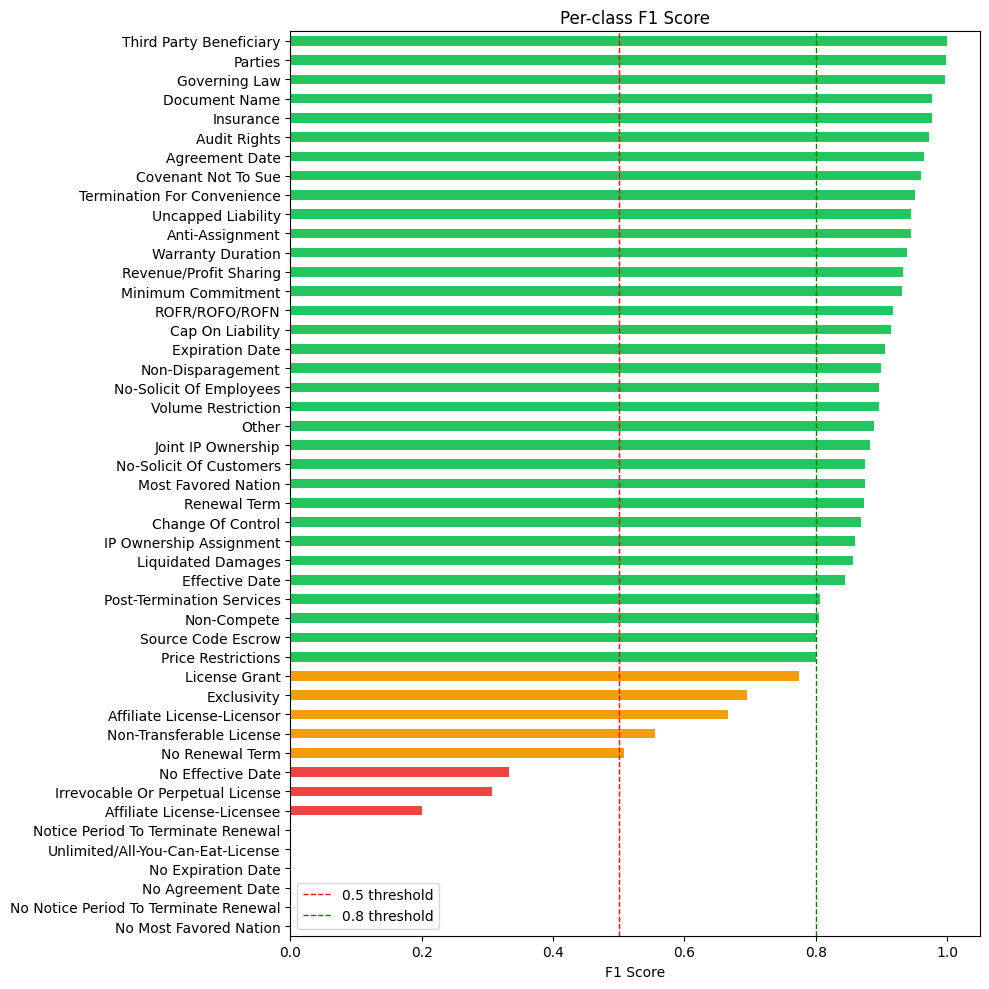

Saved → models\finetuned\evaluation/f1_per_class.png


In [12]:
f1_per_class = {
    lbl: report_dict[lbl]['f1-score']
    for lbl in label_names if lbl in report_dict
}
f1_series = pd.Series(f1_per_class).sort_values()

colors = ['#ef4444' if v < 0.5 else '#f59e0b' if v < 0.8 else '#22c55e'
          for v in f1_series]

fig, ax = plt.subplots(figsize=(10, 10))
f1_series.plot(kind='barh', ax=ax, color=colors)
ax.axvline(0.5, color='red',   linestyle='--', linewidth=1, label='0.5 threshold')
ax.axvline(0.8, color='green', linestyle='--', linewidth=1, label='0.8 threshold')
ax.set_xlabel('F1 Score')
ax.set_title('Per-class F1 Score')
ax.legend()
plt.tight_layout()
plt.savefig(EVAL_OUT / 'f1_per_class.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → {EVAL_OUT}/f1_per_class.png')